In [1]:
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)

con = duckdb.connect(str(ROOT / "warehouse.duckdb"), read_only=True)
df = con.execute("SELECT * FROM mart.bookings_enriched").fetchdf()
con.close()
df["arrival_date"] = pd.to_datetime(df["arrival_date"])
print(df.shape)

(119209, 41)


In [2]:
SPLIT_DATE = "2017-01-01"
train = df[df["arrival_date"] < SPLIT_DATE].copy()
test = df[df["arrival_date"] >= SPLIT_DATE].copy()
print(f"train: {len(train):,} rows, {train.is_canceled.mean():.1%} cancelled")
print(f"test:  {len(test):,} rows, {test.is_canceled.mean():.1%} cancelled")

train: 78,590 rows, 36.2% cancelled
test:  40,619 rows, 38.7% cancelled


In [3]:
NUMERIC = ["lead_time", "adults", "children", "babies", "total_nights",
           "previous_cancellations", "previous_bookings_not_canceled",
           "is_repeated_guest", "days_in_waiting_list", "adr", "arrival_month"]
CATEGORICAL = ["hotel", "deposit_type", "market_segment", "distribution_channel",
               "customer_type", "meal", "reserved_room_type", "country_grp"]
BOOLEAN = ["has_agent", "has_company"]

# keep the 10 most common countries (from training data only), group the rest
top_countries = train["country"].value_counts().head(10).index
for d in (train, test):
    d["country_grp"] = d["country"].where(d["country"].isin(top_countries), "Other")

def make_xy(num, cat, boo, tr=None, te=None):
    tr = train if tr is None else tr
    te = test if te is None else te
    dtr = pd.get_dummies(tr[cat])
    dte = pd.get_dummies(te[cat]).reindex(columns=dtr.columns, fill_value=0)
    Xtr = pd.concat([tr[num + boo].astype(float).fillna(0), dtr.astype(float)], axis=1)
    Xte = pd.concat([te[num + boo].astype(float).fillna(0), dte.astype(float)], axis=1)
    return Xtr, Xte

In [4]:
def evaluate(name, Xtr, Xte, ytr, yte, threshold=0.5, n_estimators=300):
    rf = RandomForestClassifier(n_estimators=n_estimators, min_samples_leaf=5,
                                n_jobs=-1, random_state=42)
    rf.fit(Xtr, ytr)
    proba = rf.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    metrics = {"model": name,
               "accuracy": accuracy_score(yte, pred),
               "precision": precision_score(yte, pred),
               "recall": recall_score(yte, pred),
               "f1": f1_score(yte, pred),
               "roc_auc": roc_auc_score(yte, proba)}
    return rf, proba, metrics

In [5]:
ytr, yte = train["is_canceled"], test["is_canceled"]
Xtr, Xte = make_xy(NUMERIC, CATEGORICAL, BOOLEAN)
rf, proba, m_main = evaluate("RF base (booking-time features)", Xtr, Xte, ytr, yte)

print(pd.Series(m_main).round(3))
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(yte, (proba >= 0.5).astype(int)))

TypeError: type str doesn't define __round__ method

In [6]:
ytr, yte = train["is_canceled"], test["is_canceled"]
Xtr, Xte = make_xy(NUMERIC, CATEGORICAL, BOOLEAN)
rf, proba, m_main = evaluate("RF base (booking-time features)", Xtr, Xte, ytr, yte)

print(pd.Series(m_main).round(3))
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(yte, (proba >= 0.5).astype(int)))

TypeError: type str doesn't define __round__ method

In [7]:
ytr, yte = train["is_canceled"], test["is_canceled"]
Xtr, Xte = make_xy(NUMERIC, CATEGORICAL, BOOLEAN)
rf, proba, m_main = evaluate("RF base (booking-time features)", Xtr, Xte, ytr, yte)

print(pd.Series({k: (round(v, 3) if not isinstance(v, str) else v) for k, v in m_main.items()}))
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(yte, (proba >= 0.5).astype(int)))

model        RF base (booking-time features)
accuracy                               0.744
precision                              0.833
recall                                 0.425
f1                                     0.563
roc_auc                                0.838
dtype: object

Confusion matrix (rows = actual, columns = predicted):
[[23548  1337]
 [ 9043  6691]]


In [8]:
m_major = {"model": "Baseline: predict nobody cancels", "accuracy": 1 - yte.mean(),
           "precision": np.nan, "recall": 0.0, "f1": 0.0, "roc_auc": 0.5}

rule = test["is_high_risk_booking"].astype(int)
m_rule = {"model": "Rule: no deposit and lead > 100 days",
          "accuracy": accuracy_score(yte, rule), "precision": precision_score(yte, rule),
          "recall": recall_score(yte, rule), "f1": f1_score(yte, rule), "roc_auc": np.nan}

display(pd.DataFrame([m_major, m_rule, m_main]).round(3))

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline: predict nobody cancels,0.613,NaN,0.000,0.000,0.500
1,Rule: no deposit and lead > 100 days,0.537,0.397,0.380,0.388,NaN
2,RF base (booking-time features),0.744,0.833,0.425,0.563,0.838


In [9]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "pct_bookings_flagged": round(100 * pred.mean(), 1),
                 "precision": precision_score(yte, pred),
                 "recall": recall_score(yte, pred)})
display(pd.DataFrame(rows).round(3))

,threshold,pct_bookings_flagged,precision,recall
0,0.3,50.9,0.616,0.810
1,0.4,35.4,0.693,0.633
2,0.5,19.8,0.833,0.425
3,0.6,12.6,0.956,0.310
4,0.7,11.0,0.984,0.279


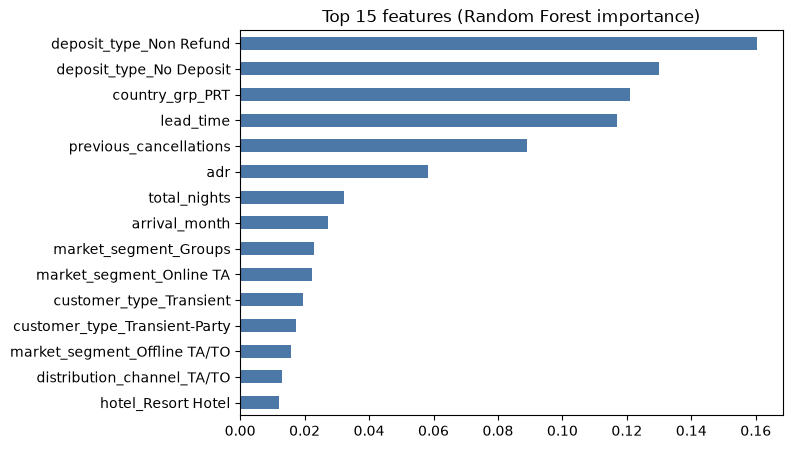

In [10]:
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
imp[::-1].plot.barh(ax=ax, color="#4C78A8")
ax.set_title("Top 15 features (Random Forest importance)")
fig.savefig(DOCS / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# a) Remove the odd 'Non Refund' bookings
tr2 = train[train["deposit_type"] != "Non Refund"]
te2 = test[test["deposit_type"] != "Non Refund"]
X2a, X2b = make_xy(NUMERIC, CATEGORICAL, BOOLEAN, tr2, te2)
_, _, m_nr = evaluate("RF base, Non Refund rows removed", X2a, X2b,
                      tr2["is_canceled"], te2["is_canceled"])

# b) Add special requests
num_req = NUMERIC + ["total_of_special_requests"]
X3a, X3b = make_xy(num_req, CATEGORICAL, BOOLEAN)
_, _, m_req = evaluate("RF + special requests", X3a, X3b, ytr, yte)

# c) Add the suspicious fields to see leakage in action
num_leak = num_req + ["required_car_parking_spaces", "booking_changes"]
X4a, X4b = make_xy(num_leak, CATEGORICAL, BOOLEAN)
_, _, m_leak = evaluate("RF + parking + booking changes (LEAKY, do not use)",
                        X4a, X4b, ytr, yte, n_estimators=150)

results = pd.DataFrame([m_major, m_rule, m_main, m_nr, m_req, m_leak]).round(3)
display(results)
results.to_csv(DOCS / "model_metrics.csv", index=False)

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline: predict nobody cancels,0.613,NaN,0.000,0.000,0.500
1,Rule: no deposit and lead > 100 days,0.537,0.397,0.380,0.388,NaN
2,RF base (booking-time features),0.744,0.833,0.425,0.563,0.838
3,"RF base, Non Refund rows removed",0.716,0.662,0.219,0.329,0.782
4,RF + special requests,0.767,0.791,0.540,0.642,0.852
5,"RF + parking + booking changes (LEAKY, do not ...",0.779,0.807,0.566,0.665,0.867


In [12]:
print("=== Cell 7: threshold table ===")
print(pd.DataFrame(rows).round(3).to_string(index=False))

=== Cell 7: threshold table ===
 threshold  pct_bookings_flagged  precision  recall
       0.3                  50.9      0.616   0.810
       0.4                  35.4      0.693   0.633
       0.5                  19.8      0.833   0.425
       0.6                  12.6      0.956   0.310
       0.7                  11.0      0.984   0.279


In [13]:
print("\n=== Cell 9: results table ===")
print(results.to_string(index=False))


=== Cell 9: results table ===
                                             model  accuracy  precision  recall    f1  roc_auc
                  Baseline: predict nobody cancels     0.613        NaN   0.000 0.000    0.500
              Rule: no deposit and lead > 100 days     0.537      0.397   0.380 0.388      NaN
                   RF base (booking-time features)     0.744      0.833   0.425 0.563    0.838
                  RF base, Non Refund rows removed     0.716      0.662   0.219 0.329    0.782
                             RF + special requests     0.767      0.791   0.540 0.642    0.852
RF + parking + booking changes (LEAKY, do not use)     0.779      0.807   0.566 0.665    0.867


In [14]:
rules = {
    "lead_time > 180": test["lead_time"] > 180,
    "has prior cancellation": test["previous_cancellations"] > 0,
    "lead > 180 OR prior cancellation": (test["lead_time"] > 180) | (test["previous_cancellations"] > 0),
}
out = []
for name, flag in rules.items():
    f = flag.astype(int)
    out.append({"rule": name, "pct_flagged": round(100 * f.mean(), 1),
                "precision": precision_score(yte, f), "recall": recall_score(yte, f)})
print(pd.DataFrame(out).round(3).to_string(index=False))

                            rule  pct_flagged  precision  recall
                 lead_time > 180         20.7      0.515   0.275
          has prior cancellation          0.7      0.173   0.003
lead > 180 OR prior cancellation         21.3      0.504   0.278


In [15]:
df["has_prior"] = df["previous_cancellations"] > 0
for col in ["lead_time_bucket", "distribution_channel", "has_prior", "deposit_type"]:
    print(f"\n--- cancel rate (%) by {col} and arrival year (groups of 200+ bookings) ---")
    t = (df.groupby([col, "arrival_year"])["is_canceled"]
           .agg(["mean", "size"]).reset_index())
    t = t[t["size"] >= 200]
    print(t.pivot(index=col, columns="arrival_year", values="mean").mul(100).round(1).to_string())


--- cancel rate (%) by lead_time_bucket and arrival year (groups of 200+ bookings) ---
arrival_year      2015  2016  2017
lead_time_bucket                  
0-7 days          10.4   9.8   8.7
181+ days         74.3  54.4  51.5
31-90 days        32.0  37.1  42.3
8-30 days         23.6  27.8  30.6
91-180 days       43.4  43.5  46.6

--- cancel rate (%) by distribution_channel and arrival year (groups of 200+ bookings) ---
arrival_year          2015  2016  2017
distribution_channel                  
Corporate             25.7  18.3  25.8
Direct                18.0  17.2  17.6
TA/TO                 41.0  39.9  42.7

--- cancel rate (%) by has_prior and arrival year (groups of 200+ bookings) ---
arrival_year  2015  2016  2017
has_prior                     
False         21.4  34.3  38.9
True          99.0  85.1  17.3

--- cancel rate (%) by deposit_type and arrival year (groups of 200+ bookings) ---
arrival_year  2015  2016  2017
deposit_type                  
No Deposit    24.5  27.4  31.